# 08 · Robustness

1. Every variant ever run is in `data/results/trials.csv`, written automatically.
2. Parameters were chosen each year using only earlier data (walk-forward).
3. The 2023+ holdout was sealed in code; the configuration was committed to git
   (`docs/PREREGISTRATION.md`) before the single run.
4. The deflated Sharpe ratio corrects the holdout Sharpe for the number of variants tried.

In [1]:
import json, warnings
import pandas as pd, matplotlib.pyplot as plt
from IPython.display import Markdown, display
from shiplab import charts
from shiplab.config import DATA
warnings.filterwarnings("ignore")
pd.set_option("display.precision", 3, "display.width", 140)
R = DATA / "results"
perf = pd.read_csv(R / "performance_by_period.csv")
strat = pd.read_parquet(R / "strategy_returns.parquet")
bench = pd.read_parquet(R / "benchmark_returns.parquet")
dsr = json.load(open(R / "deflated_sharpe.json"))
def row(period, series="Strategy"):
    return perf[(perf.period == period) & (perf.series == series)].iloc[0]

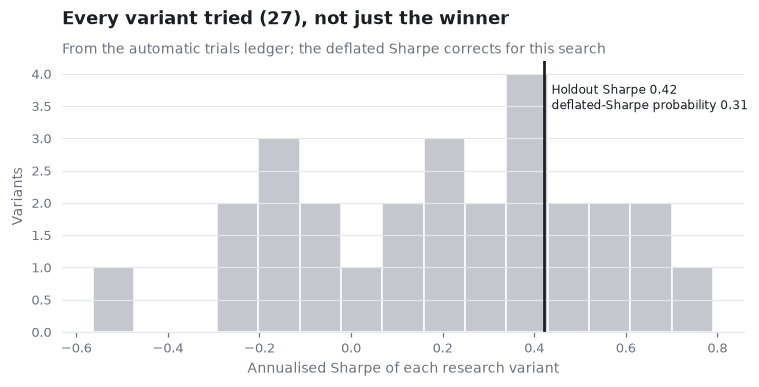

tag,capacity,holdout,reproduce,research,robustness
runs,7,1,32,27,1


In [2]:
trials = pd.read_csv(R / "trials.csv")
fig = charts.trials_histogram(trials, row("Holdout 2023-").sharpe, dsr["deflated_sharpe_probability"]["Holdout 2023-"])
charts.save(fig, "08_trials"); plt.show()
trials.groupby("tag").size().rename("runs").to_frame().T

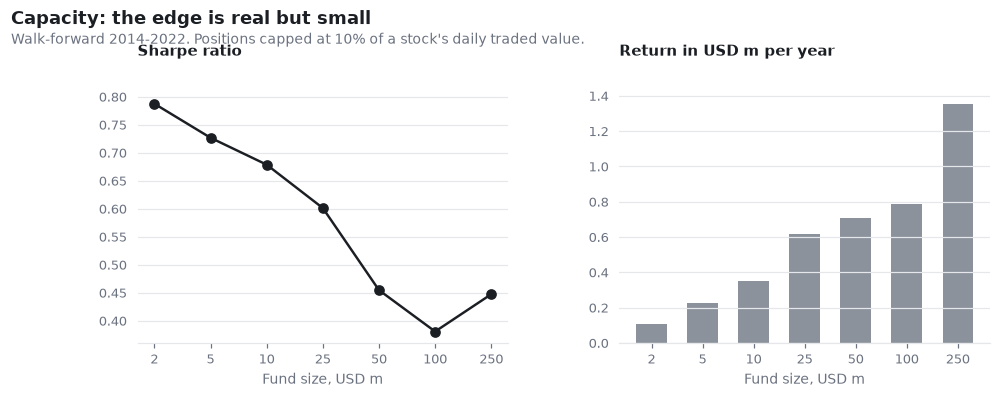

,aum_musd,sharpe,ann_return,ann_vol,avg_gross,alpha_musd_per_year
0,2.0,0.787,0.054,0.070,0.531,0.108
1,5.0,0.727,0.045,0.063,0.470,0.225
2,10.0,0.679,0.035,0.053,0.375,0.349
3,25.0,0.601,0.025,0.042,0.248,0.615
4,50.0,0.455,0.014,0.032,0.165,0.708
5,100.0,0.381,0.008,0.021,0.099,0.786
6,250.0,0.447,0.005,0.012,0.046,1.352


In [3]:
cap = pd.read_csv(R / "capacity.csv")
fig = charts.capacity(cap); charts.save(fig, "08_capacity"); plt.show()
cap.round(3)

In [4]:
perf[perf.series.isin(["Strategy", "EW shipping basket", "SPY", "BDRY", "BWET"])].pivot(
    index="series", columns="period", values="sharpe").round(2)

period,Holdout 2023-,Validation 2021-2022,Walk-forward 2014-2020
series,,,
BDRY,0.42,0.51,-0.50
BWET,1.99,NaN,NaN
EW shipping basket,1.32,1.30,-0.14
SPY,1.41,0.23,0.78
Strategy,0.42,0.61,0.70
